Classic only run for personal analysis

In [7]:
import sys
sys.path.append("../")

from src.segmentation_pipeline import segmentation_pipeline

# these modules rely on the detectron2 engine
# from src.model_run import start_prediction_machine, detectron2_instances, CLASSES
from src.fusion import *

from src.classic_instances import instance_regions, make_instance_gif
from src.classifier import classify_instances, load_classifiers, Category_Classifier
from src.coco_json_functions import *
# from src.instance_based_evaluation import compare_coco
from tqdm import tqdm

from collections import defaultdict
import cv2
import numpy as np
from matplotlib import pyplot as plt

import imagesize
from pathlib import Path


from sklearn.base import TransformerMixin, BaseEstimator
class SelectColumns(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns
    def fit(self, xs, ys, **params):
        return self
    def transform(self, xs):
        return xs[self.columns]
    
from pathlib import Path

In [8]:
# Config
####################################################################################################
# INPUT IMAGES

# this file should be for the images you want to test on. 
# It containst the image paths in the coco json format so that's why its needed, we don't take the annotations yet
input_file = "St-0_N4.png"
tangled = False

####################################################################################################
# CLASSIFIERS

bg_cls = "../models/classifiers/bg_regular_classifier.pkl"
bmp_cls = "../models/classifiers/bumps_embedded_classifier.pkl"


####################################################################################################
# OUTPuT PATHS

CLASSIC_OUTPUT = "../outputs/classic_test.json"

In [9]:
# Make the classifier class
bmp_predictor, bg_predictor = load_classifiers(bmp_cls, bg_cls)
classifier = Category_Classifier(None, None, None, None, bmp_predictor, bg_predictor, tangled)

c:\Users\trist\projects\DAAD_Tristan_Bioinformatics_2026\venv\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator MinMaxScaler from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\trist\projects\DAAD_Tristan_Bioinformatics_2026\venv\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.6.1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\trist\projects\DAAD_Tristan_Bioinformatics_2026\venv\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning:

In [10]:
# go through each 5 major setps. Look at documentation pdf or hold Ctr key when left-clicking for more info
def classic_instance_segmentation_pipeline(img_path, 
                                    max_hole_size=2000, 
                                    min_area=100, 
                                    max_distance=20, 
                                    circularity_threshold=0.8, 
                                    tangled=tangled,
                                    verbose=False, 
                                    is_stitched=False,
                                    show_overlay=True):
    
    #1. Classic Segmentation
    #   function returns the mask for the root and the mask for the hairs as seperate variables
    root, hairs = segmentation_pipeline(img_path, max_hole_size=max_hole_size, min_area=min_area, max_distance=max_distance, 
                                        circularity_threshold=circularity_threshold, verbose=verbose, 
                                        is_stitched=is_stitched, show_overlay=show_overlay) 


    # #2. Separate Classic Segments by Instance
    # #   get a list of each unique instance mask of root hairs
    classic_masks = instance_regions(hairs, root, tangled=tangled)
    
    # 3. Get the Model outputs
    #   Instances is a list of all found instances in the image, including bounding box, mask, label, and label id
    # model_instances = detectron2_instances(predictor, img_path, verbose=verbose)

    #4. Fusion
    fused_instances = fusion_of_masks(classic_masks, [], iou_threshold=5,
                                      detectron_confidence_threshold=0.0)

    # 5. Classify
    classified_instances = classify_instances(fused_instances, root, img_path, classifier, tangled)
    

    return classified_instances

In [11]:
def make_coco_outputs(img_source, save=True):

    '''
    take the predicted annotations and save as a coco json

    img_source can be two types:
    - a list of paths to your images
    - a path to a COCO json file holding file location data
    '''

    if not isinstance(img_source, list):
        #handle list
        the_path = Path(img_source)
        file_type = the_path.suffix

        if file_type == ".json":
            with open(img_source) as f: 
                train = json.load(f)


            train_names = {img["file_name"] for img in train["images"]}
            img_source = [train_names]


    all_images = []
    all_annotation_classic = []
    ann_id_classic = 0

    image_id = 0
    for img_path in tqdm(img_source, desc="Images", colour="magenta"):
        classic_instances = classic_instance_segmentation_pipeline(img_path, show_overlay=False)
        # classic_instances_list = [{"mask": m["mask"], "case": "B"} for m in classic_masks]

        # print(classic_instances_list)

        #get height and width of image
        width, height = imagesize.get(img_path)

        all_images.append({
            "id": image_id,
            "file_name": img_path,
            "width": width,
            "height": height
        })

        anns_c, ann_id_classic = build_annotations_for_image(classic_instances, image_id, ann_id_classic, epsilon=0.0)
        all_annotation_classic.extend(anns_c)

        image_id += 1

    if save:
        write_coco_dataset(all_images, all_annotation_classic, CLASSES, CLASSIC_OUTPUT)

    return classic_instances

In [12]:
# classic_masks = classic_instance_segmentation_pipeline(input_file, verbose=True)
classic_instances = make_coco_outputs([input_file], save=True)

Images: 100%|██████████| 1/1 [00:20<00:00, 20.02s/it]


# display

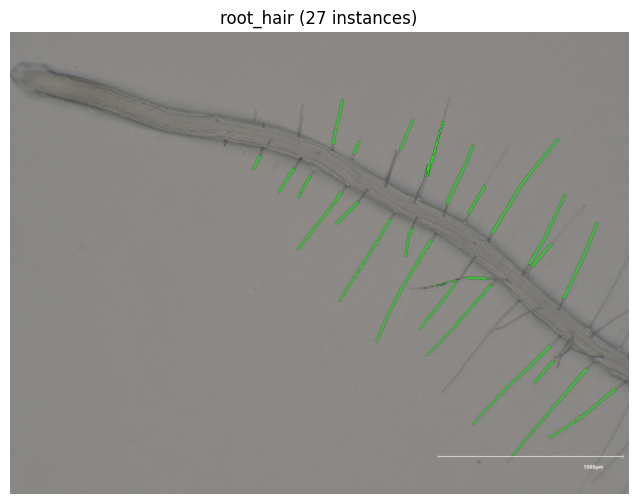

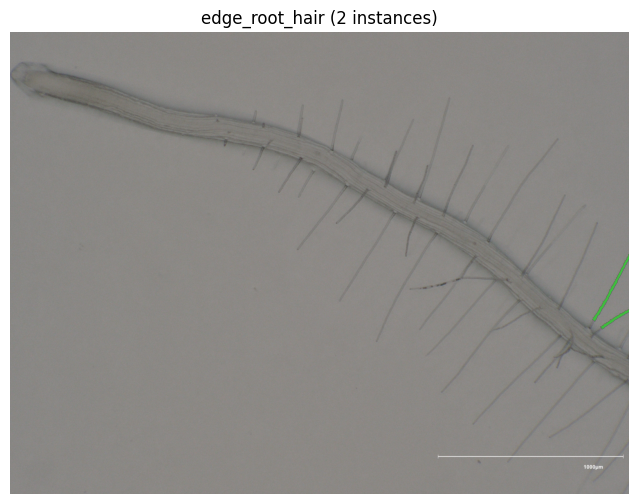

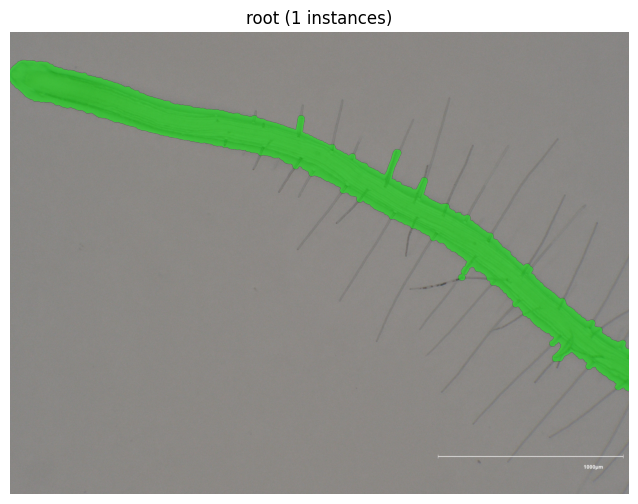

In [13]:
image = cv2.imread(input_file)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Group masks by category
masks_by_category = defaultdict(list)
for instance in classic_instances:
    masks_by_category[instance["category_id"]].append(instance["mask"])

# Plot one figure per category, with all its masks overlaid
for cat_id, mask_list in masks_by_category.items():
    cat_name = CLASSES[cat_id]
    
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(image)
    
    for mask in mask_list:
        overlay = np.zeros((*mask.shape, 4), dtype=np.uint8)
        overlay[mask] = (0, 255, 0, 128) 
        ax.imshow(overlay)
    
    ax.axis("off")
    ax.set_title(f"{cat_name} ({len(mask_list)} instances)")
    plt.show()